# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Савков Олександр'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 6      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам’янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 6: Чернівці, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_чернівці


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}
MIRRORS = ['https://overpass-api.de/api',
           'https://overpass.private.coffee/api',
           'https://z.overpass-api.de/api']
PROBE = '[out:json][timeout:10];node(48.2900,25.9300,48.2901,25.9301);out count;'
LIVE_PATH = os.path.join(OUT, 'cost_live.json')


def working_mirror(rounds=15, pause=60):
    import requests
    for _ in range(rounds):
        for base in MIRRORS:
            try:
                r = requests.post(base + '/interpreter', data={'data': PROBE},
                                  headers={'User-Agent': USER_AGENT}, timeout=30)
            except requests.RequestException:
                continue
            if r.status_code == 200 and r.text.lstrip().startswith('{'):
                return base
        time.sleep(pause)
    raise RuntimeError('жодне дзеркало Overpass не відповідає')


def remember_live(name, row):
    live = {}
    if os.path.exists(LIVE_PATH):
        with open(LIVE_PATH, encoding='utf-8') as f:
            live = json.load(f)
    live[name] = row
    with open(LIVE_PATH, 'w', encoding='utf-8') as f:
        json.dump(live, f, ensure_ascii=False, indent=1)


if not os.path.exists(os.path.join(OUT, 'road_nodes.parquet')):
    ox.settings.overpass_url = working_mirror()


def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    for attempt in range(5):
        t0, b0 = time.time(), cache_bytes()
        try:
            g = clean(getter())
            break
        except Exception:
            if attempt == 4:
                raise
            time.sleep(60)
            ox.settings.overpass_url = working_mirror()
    g.to_parquet(path, index=False)
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 1)}
    remember_live(name, COST[name])
    return gpd.read_parquet(path)

In [7]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 151.4 км²


In [8]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 14240 | ребер 37950


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [9]:
display(pd.DataFrame(COST).T)

if COST['мережа walk']['спосіб'] == 'живий запит':
    remember_live('мережа walk', COST['мережа walk'])
with open(LIVE_PATH, encoding='utf-8') as f:
    live = pd.DataFrame(json.load(f)).T
now = pd.DataFrame(COST).T
display(pd.DataFrame({'перший запуск, МБ': live['передано_МБ'], 'перший запуск, с': live['секунд'],
                      'цей запуск': now['спосіб'], 'цей запуск, МБ': now['передано_МБ'],
                      'цей запуск, с': now['секунд'], 'файл, МБ': now['файл_МБ']}))
live_s, live_mb, now_s = live['секунд'].sum(), live['передано_МБ'].sum(), now['секунд'].sum()
speedup = live_s / now_s
print('живий запит %.1f с і %.2f МБ, цей запуск %.2f с, швидше у %.0f разів' % (live_s, live_mb, now_s, speedup))

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.034,0.168
heritage,знімок,93,0.0,0.046,0.017
stations,знімок,8,0.0,0.032,0.015
amenities,знімок,294,0.0,0.064,0.018
мережа walk,знімок,52190,0.0,2.947,0.083


,"перший запуск, МБ","перший запуск, с",цей запуск,"цей запуск, МБ","цей запуск, с","файл, МБ"
boundary,0.035,2.4,знімок,0.0,0.168,0.034
heritage,0.045,102.0,знімок,0.0,0.017,0.046
stations,0.012,87.2,знімок,0.0,0.015,0.032
amenities,0.09,78.1,знімок,0.0,0.018,0.064
мережа walk,7.092,69.8,знімок,0.0,0.083,2.947


живий запит 339.5 с і 7.27 МБ, цей запуск 0.30 с, швидше у 1128 разів


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [10]:
GENERIC_NAMES = ['Меморіальна дошка', 'Стадіон', 'Вуличне мистецтво']
DUPLICATE_IDS = [6211071385]

tags_ok = heritage['historic'].notna() | heritage['tourism'].isin(TOURISM_OK)
named = heritage['name'].notna() & (heritage['name'].str.strip() != '')
plaque = heritage['memorial'].isin(['plaque'])
generic = heritage['name'].isin(GENERIC_NAMES)
duplicate = heritage['id'].isin(DUPLICATE_IDS)
mask = tags_ok
cand = heritage[mask & named & ~plaque & ~generic & ~duplicate].reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(tags_ok.sum()))
print('з них мають name       :', int((tags_ok & named).sum()))

steps = [('не historic і не tourism зі списку', tags_ok),
         ('немає name', named),
         ('memorial=plaque, дошка на стіні', ~plaque),
         ('назва лише повторює тип об’єкта', ~generic),
         ('дублікат, та сама назва за 5 м', ~duplicate)]
left, rows = pd.Series(True, index=heritage.index), []
for rule, keep in steps:
    rows.append({'правило': rule, 'відкинуто': int((left & ~keep).sum()), 'лишилось': int((left & keep).sum())})
    left = left & keep
display(pd.DataFrame(rows).set_index('правило'))

unnamed = heritage[tags_ok & ~named]
display(unnamed['historic'].fillna(unnamed['tourism']).value_counts().rename('без name').to_frame().T)
display(unnamed.loc[unnamed['description'].notna() | unnamed['name:uk'].notna(), ['id', 'historic', 'tourism', 'description', 'name:uk']])

усього у шарі heritage : 93
підходять за тегами    : 93
з них мають name       : 72


,відкинуто,лишилось
правило,,
не historic і не tourism зі списку,0,93
немає name,21,72
"memorial=plaque, дошка на стіні",5,67
назва лише повторює тип об’єкта,3,64
"дублікат, та сама назва за 5 м",1,63


historic,memorial,attraction,railway_car,monument,artwork,viewpoint,tomb
без name,7,5,4,2,1,1,1


,id,historic,tourism,description,name:uk
83,13943605201,NaN,attraction,NaN,Прапор
86,159474035,tomb,NaN,Ohel Ruzhin,NaN


In [11]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial          27
monument           6
castle             1
church             1
wayside_shrine     1

=== tourism ===
tourism
museum        12
attraction     9
artwork        3
viewpoint      3
gallery        1

типи геометрії: {'Point': 59, 'Polygon': 4}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [12]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

WRONG_WIKIDATA = ['Q20083620', 'Q60174665']
NAME_COLUMNS = [c for c in cand.columns if c.startswith('name:')]
WEIGHTS = {'wiki': 0.35, 'n_lang_pct': 0.25, 'museum': 0.20, 'has_historic': 0.15, 'area_pct': 0.05}

cand['wiki'] = (cand['wikipedia'].notna()
                | (cand['wikidata'].notna() & ~cand['wikidata'].isin(WRONG_WIKIDATA))).astype(int)
cand['n_lang'] = cand[NAME_COLUMNS].notna().sum(axis=1)
cand['n_lang_pct'] = cand['n_lang'].rank(pct=True)
cand['museum'] = cand['tourism'].isin(['museum', 'gallery']).astype(int)
cand['has_historic'] = cand['historic'].notna().astype(int)
cand['area_pct'] = cand['area_m2'].rank(pct=True)
cand['score'] = sum(w * cand[c] for c, w in WEIGHTS.items())

anchor = metric.geometry.representative_point()
XY_CAND = np.c_[anchor.x.values, anchor.y.values]
cand['neighbours'] = (np.sqrt(((XY_CAND[:, None, :] - XY_CAND[None, :, :]) ** 2).sum(-1)) < 300).sum(axis=1) - 1

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()), '(ще %d з хибним wikidata)' % int(cand['wikidata'].isin(WRONG_WIKIDATA).sum()))
print('мають площу  :', int((cand['area_m2'] > 0).sum()))

кандидатів   : 63
мають wiki   : 5 (ще 2 з хибним wikidata)
мають площу  : 4


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [13]:
N_SMALL, N_LARGE = 10, 30

top_score = (cand.sort_values(['score', 'neighbours', 'id'], ascending=[False, False, True])
             .head(N_LARGE).reset_index(drop=True))
top10 = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)
overlap = len(set(top10['id']) & set(top_naive['id']))
overlap_real = len(set(top10['id']) & set(top_naive.loc[top_naive['area_m2'] > 0, 'id']))
border = cand['score'].round(9) == round(top_score['score'].iloc[-1], 9)

print('перетин: %d з %d, із площею більше нуля: %d' % (overlap, N_SMALL, overlap_real))
print('на межі топ-30 однаковий бал мають %d об’єктів, у топ-30 з них %d'
      % (border.sum(), (top_score['score'].round(9) == round(top_score['score'].iloc[-1], 9)).sum()))
display(pd.DataFrame({'за вашим критерієм': list(top10['name']),
                      'бал': top10['score'].round(3).values,
                      'за площею': list(top_naive['name']),
                      'площа, м²': top_naive['area_m2'].round(0).values}))

перетин: 4 з 10, із площею більше нуля: 3
на межі топ-30 однаковий бал мають 30 об’єктів, у топ-30 з них 9


,за вашим критерієм,бал,за площею,"площа, м²"
0,Костел Воздвиження Святого Христа,0.790,Костел Воздвиження Святого Христа,1115.0
1,Музей Володимира Івасюка,0.788,Музей Буковинської Діаспори,473.0
2,Музей Буковинської Діаспори,0.698,Церква Покрови Пресвятої Діви Марії,167.0
3,Музей пожежно-рятувальної справи,0.673,Турецька криниця,85.0
4,Турецька криниця,0.497,Художній музей,0.0
5,Художній музей,0.464,Музей Народної Архітектури,0.0
6,Музей етнографії та стародавньої історії,0.464,Пам’ятник загиблим в Афганістані,0.0
7,Музей історії та культури євреїв Буковини,0.438,Пам'ятник Юрію Федьковичу,0.0
8,Чернівецький літературно-меморіальний музей Ол...,0.438,Краєзнавчий музей,0.0
9,Музей Авіації та Космонавтики,0.438,Пам'ятник Т.Г.Шевченку,0.0


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [14]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

known = gpd.GeoDataFrame(geometry=gpd.points_from_xy([25.9300, 25.9304, 25.9500], [48.29, 48.29, 48.29]),
                         crs='EPSG:4326')
assert [(i, j) for i, j, _ in close_pairs(known)] == [(0, 1)]

pairs = pd.DataFrame([{'перша': top_score['name'].iloc[i], 'друга': top_score['name'].iloc[j], 'метрів': round(d, 1)}
                      for i, j, d in close_pairs(top_score)])
pairs['рішення'] = 'лишити обидва: різні об’єкти'
display(pairs)

,перша,друга,метрів,рішення
0,Пам'ятник Ференцу Лісту,Пам'ятник Чорний квадрат Малевича,16.4,лишити обидва: різні об’єкти
1,Музей історії та культури євреїв Буковини,Пам'ятник Ользі Кобилянській,50.5,лишити обидва: різні об’єкти
2,Костел Воздвиження Святого Христа,600 років моєму рідному місту,54.1,лишити обидва: різні об’єкти


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [15]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 8
                            name  railway       building
0              Чернівці-Північна  station            NaN
1                       Чернівці  station            NaN
2                    Калинівська  station            NaN
3                        Садгора  station            NaN
4              Чернівці-Південна  station            NaN
5                            NaN      NaN  train_station
6  Залізничний вокзал "Чернівці"      NaN  train_station
7                            NaN      NaN  train_station


In [16]:
station = stations[stations['id'] == 99408856]
print('старт:', station['name'].iloc[0])

старт: Залізничний вокзал "Чернівці"


In [17]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 14240 вузлів, 37456 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [18]:
def check_snap(points, ids, dist, label):
    print('%s: точок %d, різних вузлів %d, відстань до вузла: медіана %.0f м, максимум %.0f м'
          % (label, len(ids), len(set(ids)), np.median(dist), np.max(dist)))
    if len(set(ids)) < len(ids):
        groups = pd.Series(points['name'].values).groupby(ids).agg(list)
        for names in groups[groups.map(len) > 1]:
            print('  злиплись:', ' + '.join(names))

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [19]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    m = points.to_crs(32635).geometry
    XY = np.c_[m.x.values, m.y.values]
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))

def detour_factor(D, E):
    ok = np.isfinite(D) & (D > 0) & (E > 0)
    return float(np.median(D[ok] / E[ok]))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [20]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

мала задача: точок 11, різних вузлів 11, відстань до вузла: медіана 16 м, максимум 81 м


матриця за 0.195 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.20


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [21]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    tour, left = [0], set(range(1, len(D)))
    while left:
        nearest = min(left, key=lambda j: (D[tour[-1], j], j))
        tour.append(nearest)
        left.remove(nearest)
    return tour + [0]

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best, best_len = list(tour), tour_length(D, tour)
    improved = True
    while improved:
        improved = False
        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):
                trial = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                trial_len = tour_length(D, trial)
                if trial_len < best_len - 1e-9:
                    best, best_len = trial, trial_len
                    improved = True
    return best

In [22]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [23]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [24]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,16887,11.88
2-opt,15205,0.73
Held-Karp (точний),15094,0.00



оптимальний порядок:
   0. СТАРТ: Залізничний вокзал "Чернівці"
   1. Музей Буковинської Діаспори
   2. Музей етнографії та стародавньої історії
   3. Музей історії та культури євреїв Буковини
   4. Художній музей
   5. Музей пожежно-рятувальної справи
   6. Музей Авіації та Космонавтики
   7. Чернівецький літературно-меморіальний музей Ольги Кобилянської
   8. Музей Володимира Івасюка
   9. Турецька криниця
  10. Костел Воздвиження Святого Христа
  11. СТАРТ: Залізничний вокзал "Чернівці"

довжина: 15.09 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [25]:
growth = pd.DataFrame({'точок': [11, 16, 21, 26, 31]})
growth['клітин'] = 2 ** (growth['точок'] - 1) * (growth['точок'] - 1)
growth['пам’ять, ГБ'] = (growth['клітин'] * 8 / 1e9).round(4)
growth['операцій'] = growth['клітин'] * (growth['точок'] - 1)
display(growth.set_index('точок').style.format({'клітин': '{:.2e}', 'пам’ять, ГБ': '{:.4f}', 'операцій': '{:.2e}'}))

,клітин,"пам’ять, ГБ",операцій
точок,,,
11,1.02e+04,0.0001,1.02e+05
16,4.92e+05,0.0039,7.37e+06
21,2.10e+07,0.1678,4.19e+08
26,8.39e+08,6.7109,2.10e+10
31,3.22e+10,257.6980,9.66e+11


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [26]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

велика задача: точок 31, різних вузлів 30, відстань до вузла: медіана 16 м, максимум 81 м
  злиплись: Пам'ятник Ференцу Лісту + Пам'ятник Чорний квадрат Малевича


коефіцієнт обходу: 1.24
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    42362 м
2-opt            :    37191 м  за 0.008 с  (коротше на 12.2%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м
кандидатів 63 у 39 комірках; половина лежить у 10 комірках, це 1.05 км² або 0.7% площі міста


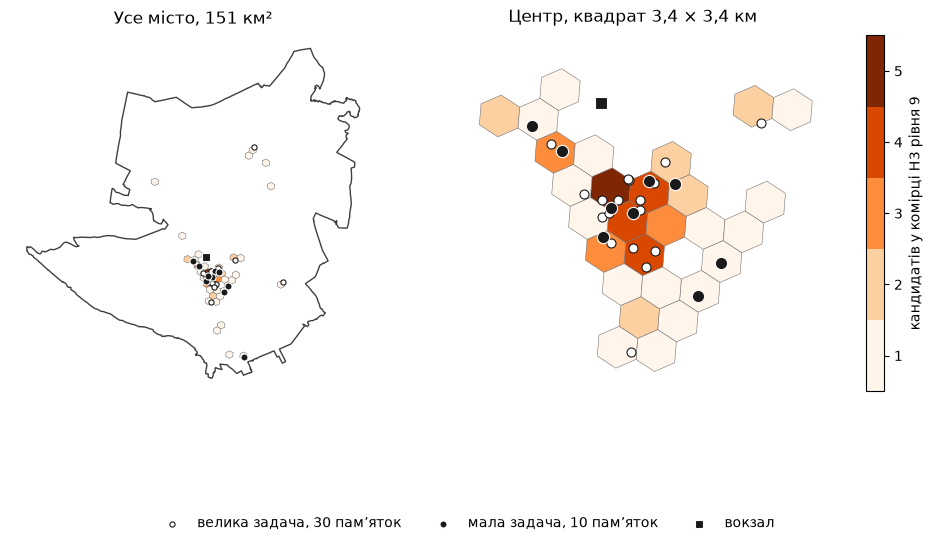

In [27]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

anchors = cand.geometry.representative_point()
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in anchors]
dens = cand['h3'].value_counts()
hexes = gpd.GeoDataFrame({'count': dens.values},
                         geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)])
                                   for c in dens.index],
                         crs='EPSG:4326')

cells_half = int((dens.cumsum() / dens.sum() < 0.5).sum()) + 1
area_half = cells_half * h3.average_hexagon_area(H3_RES, unit='km^2')
area_city = boundary.to_crs(32635).area.iloc[0] / 1e6
print('кандидатів %d у %d комірках; половина лежить у %d комірках, це %.2f км² або %.1f%% площі міста'
      % (dens.sum(), len(dens), cells_half, area_half, 100 * area_half / area_city))

hexes_m, boundary_m = hexes.to_crs(32635), boundary.to_crs(32635)
pts10_m, pts30_m = pts10.to_crs(32635), pts30.to_crs(32635)
cmap = plt.get_cmap('Oranges', dens.max())
fig, axes = plt.subplots(1, 2, figsize=(13, 6.6))
for ax, size in zip(axes, (1, 3)):
    hexes_m.plot(ax=ax, column='count', cmap=cmap, vmin=0.5, vmax=dens.max() + 0.5, edgecolor='0.45', linewidth=0.4)
    boundary_m.boundary.plot(ax=ax, color='0.25', linewidth=1)
    pts30_m.iloc[1:].plot(ax=ax, color='white', edgecolor='0.1', markersize=14 * size, linewidth=0.8,
                          label='велика задача, 30 пам’яток')
    pts10_m.iloc[1:].plot(ax=ax, color='0.1', edgecolor='white', markersize=26 * size, linewidth=0.8,
                          label='мала задача, 10 пам’яток')
    pts10_m.iloc[:1].plot(ax=ax, color='0.1', edgecolor='white', marker='s', markersize=26 * size, linewidth=0.8,
                          label='вокзал')
    ax.set_axis_off()
centre = pts10_m.geometry.iloc[6]
axes[1].set_xlim(centre.x - 1700, centre.x + 1700)
axes[1].set_ylim(centre.y - 1700, centre.y + 1700)
axes[0].set_title('Усе місто, %.0f км²' % area_city)
axes[1].set_title('Центр, квадрат 3,4 × 3,4 км')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, frameon=False)
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0.5, dens.max() + 0.5), cmap=cmap), ax=axes,
             ticks=range(1, dens.max() + 1), label='кандидатів у комірці H3 рівня 9', shrink=0.7)
plt.show()

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [28]:
near = gpd.sjoin_nearest(pts10.to_crs(32635),
                         amenities.to_crs(32635)[['name', 'amenity', 'geometry']],
                         how='left', distance_col='distance_m', lsuffix='point', rsuffix='place')
near = near[~near.index.duplicated()]
display(pd.DataFrame({'точка маршруту': near['name_point'],
                      'найближчий заклад': near['name_place'].fillna('без назви'),
                      'тип': near['amenity'],
                      'відстань, м': near['distance_m'].round(0).astype(int)}))
print('медіана %.0f м, максимум %.0f м' % (near['distance_m'].median(), near['distance_m'].max()))

,точка маршруту,найближчий заклад,тип,"відстань, м"
0,"СТАРТ: Залізничний вокзал ""Чернівці""",без назви,toilets,33
1,Костел Воздвиження Святого Христа,Гауптвахта,cafe,24
2,Музей Володимира Івасюка,Гарячий Чебурек,restaurant,348
3,Музей Буковинської Діаспори,без назви,toilets,146
4,Музей пожежно-рятувальної справи,Долина Плюс питна вода,drinking_water,57
5,Турецька криниця,La Multi ani,restaurant,130
6,Художній музей,Літературне кафе,cafe,10
7,Музей етнографії та стародавньої історії,без назви,toilets,35
8,Музей історії та культури євреїв Буковини,YOKI,restaurant,40
9,Чернівецький літературно-меморіальний музей Ол...,Гарячий Чебурек,restaurant,173


медіана 57 м, максимум 348 м


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [29]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

from shapely.geometry import LineString

shortest = edges.sort_values('length').drop_duplicates(['u', 'v']).set_index(['u', 'v'])['geometry']

def street_coords(tour, ids):
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        for u, v in zip(path[:-1], path[1:]):
            xy = list(shortest.loc[(u, v)].coords)
            start = node_xy.loc[u]
            if abs(xy[0][0] - start['x']) + abs(xy[0][1] - start['y']) > abs(xy[-1][0] - start['x']) + abs(xy[-1][1] - start['y']):
                xy = xy[::-1]
            coords += [(lat, lon) for lon, lat in xy]
    return coords

def line_length_m(coords):
    line = LineString([(lon, lat) for lat, lon in coords])
    return float(gpd.GeoSeries([line], crs='EPSG:4326').to_crs(32635).length.iloc[0])

street = street_coords(ex10, ids10)
straight = [(pts10.geometry.y.iloc[i], pts10.geometry.x.iloc[i]) for i in ex10]
L_street, L_nodes, L_straight = line_length_m(street), line_length_m(route_coords(ex10, ids10)), line_length_m(straight)
print('лінія вулицями %.0f м, через самі вузли %.0f м, матриця %.0f м, прямі відрізки %.0f м, вулицями довше на %.1f%%'
      % (L_street, L_nodes, L_opt, L_straight, 100 * (L_street / L_straight - 1)))

ex_straight, _ = held_karp(E10)
print('порядок із матриці прямих, пройдений вулицями: %.0f м, на %.2f%% довше оптимуму'
      % (tour_length(D10, ex_straight), 100 * (tour_length(D10, ex_straight) / L_opt - 1)))

stop_cost = pd.Series({pts10['name'].iloc[i]: L_opt - held_karp(np.delete(np.delete(D10, i, 0), i, 1))[1]
                       for i in range(1, len(D10))}).sort_values(ascending=False)
display(pd.DataFrame({'без цієї зупинки коротше, м': stop_cost.round(0).astype(int),
                      'частка маршруту, %': (100 * stop_cost / L_opt).round(1)}))

fmap = folium.Map(tiles=BASEMAP,
                  attr=BASEMAP.html_attribution + ' | Дані © OpenStreetMap contributors, ліцензія ODbL')
folium.PolyLine(street, color='#1f4e9c', weight=5, opacity=0.85, tooltip='маршрут по ребрах графа').add_to(fmap)
folium.PolyLine(straight, color='#d1341f', weight=2.5, dash_array='7 6', tooltip='прямі відрізки').add_to(fmap)
for step, i in enumerate(ex10[:-1]):
    p = pts10.geometry.iloc[i]
    label = 'В' if i == 0 else str(step)
    folium.Marker([p.y, p.x], tooltip='%s. %s' % (label, pts10['name'].iloc[i]),
                  icon=folium.DivIcon(html='<div style="width:24px;height:24px;border-radius:50%%;background:#111;'
                                           'color:#fff;font:bold 13px/24px sans-serif;text-align:center">%s</div>' % label,
                                      icon_size=(24, 24), icon_anchor=(12, 12))).add_to(fmap)
fmap.fit_bounds([[min(c[0] for c in street), min(c[1] for c in street)],
                 [max(c[0] for c in street), max(c[1] for c in street)]])
fmap.save('lr5_маршрут.html')
fmap

лінія вулицями 15106 м, через самі вузли 15007 м, матриця 15094 м, прямі відрізки 12469 м, вулицями довше на 21.2%
порядок із матриці прямих, пройдений вулицями: 15094 м, на 0.00% довше оптимуму


,"без цієї зупинки коротше, м","частка маршруту, %"
Музей Авіації та Космонавтики,7328,48.5
Музей Буковинської Діаспори,739,4.9
Музей пожежно-рятувальної справи,452,3.0
Музей Володимира Івасюка,437,2.9
Художній музей,432,2.9
Турецька криниця,273,1.8
Костел Воздвиження Святого Христа,215,1.4
Музей історії та культури євреїв Буковини,179,1.2
Музей етнографії та стародавньої історії,129,0.9
Чернівецький літературно-меморіальний музей Ольги Кобилянської,8,0.1


---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [30]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (16.2 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [31]:
def comma(value, digits):
    return ('%.*f' % (digits, value)).replace('.', ',')

REPORT = f'''
1. Відкинув 30 об’єктів із 93, і без пояснень замовнику цей фільтр не віддав би. За тегами не відпало нічого, бо запит і так повернув лише historic і tourism зі списку, 21 об’єкт випав через відсутній name, 5 мають memorial=plaque, тобто це дошка на стіні, а не окрема зупинка, 3 мають назву, що лише повторює тип («Меморіальна дошка», «Стадіон», «Вуличне мистецтво»), і це те саме, що без назви, ще 1 є дублем «Німецького будинку» за 5 м. Лишилось 63 кандидати, 59 точок і 4 полігони. Пояснення потрібне, бо правило name викидає і справжні місця: серед 21 безіменного є гробниця в Садгорі, де «Ohel Ruzhin» записано лише в description, і 4 вагони historic=railway_car біля паротягів. Живий запит передав {comma(live_mb, 2)} МБ за {comma(live_s, 0)} с, знімок читається за {comma(now_s, 2)} с без трафіку, це швидше у {comma(speedup, 0)} разів.

2. У рейтингу п’ять сигналів: wiki 0,35, кількість name:* 0,25, музей або галерея 0,20, заповнений historic 0,15, площа 0,05, причому кількість мов і площу зведено через rank(pct=True) до частки від 0 до 1. Найбільша вага у wiki, бо це єдиний сигнал із джерела поза OSM, а більше 0,35 не дав, бо 2 теги wikidata із 7 ведуть на інший об’єкт, і ці два я занулив. Переклади на другому місці, бо їх додає інша людина, але 49 кандидатів із 63 мають лише одну мову, і в 62 із 63 name:uk просто копіює name, тож сигнал розрізняє слабко. Музей має 0,20, бо він за призначенням для відвідування, хоча про якість нічого не каже. historic є у 36 із 63 і лише відсікає сучасне, тому 0,15. Площа найслабша і ненульова лише в 4 кандидатів, бо решта вузли, тому 0,05. Формула не розрізняє всіх: 30 кандидатів мають однаковий бал 0,273, межа топ-30 проходить крізь них, і серед рівних я беру тих, у кого більше сусідів у радіусі 300 м, бо маршрут піший, а 9 місць топ-30 визначені саме так. На топ-10 це не впливає.

3. Збіглось 4 з 10, але чесно лише 3: костел, Музей Буковинської Діаспори і Турецька криниця. Площу більшу за нуль мають лише 4 кандидати, тому рейтинг за площею взагалі не може назвати десятку: решта 6 його місць це вузли з площею 0, які nlargest бере в порядку таблиці, звідси випадковий збіг «Художнього музею» і «Пам’ятник загиблим в Афганістані» у списку. Для слова «найкращі» це означає, що воно задане критерієм, а не даними: у моєму топ-10 аж 8 музеїв, бо я сам дав музеям 0,20. Ціну такого вибору видно в метрах: Музей авіації має бал 0,438 завдяки одному тегу name:ru, без нього було б 0,323 і поза десяткою, а ця одна зупинка дає 7 328 м, тобто 48,5 % довжини маршруту, без неї 7 766 м замість 15 094 м.

4. Коефіцієнт обходу 1,20 на 10 точках і 1,24 на 30, це типово, але на нижній межі звичних 1,2–1,6, і причина конкретна: до Музею авіації майже прямо веде вулиця Головна, тому всі його пари дають 1,04–1,17, а без нього коефіцієнт 1,22. Найбільші значення біля вокзалу: до Музею етнографії 2,45, до Музею Буковинської Діаспори 2,34, це 1 576 м вулицями проти 675 м прямо, бо між ними парк Федьковича на схилі, який доводиться огинати. Автомобільна мережа тут ні до чого: усі 37 950 ребер мають oneway=False, тому асиметрія 0 м (точно 5·10⁻¹² м, похибка додавання), а inf немає, бо граф є одним компонентом на 14 240 вузлів. Намальована лінія 15 106 м збігається з матрицею 15 094 м на 0,08 %, прямі дають 12 469 м, тобто вулицями довше на 21,2 %. Неочікувано інше: Held–Karp лише за матрицею прямих знайшов той самий порядок обходу, різниця 0,00 %, тож на цих 10 точках пряма лінія бреше про довжину, але не про порядок.

5. Найближчий сусід гірший за точний розв’язок на 11,88 %: 16 887 м проти 15 094 м, а 2-opt лише на 0,73 %, 15 205 м. Саме число не здивувало, бо причину видно на картограмі: половина кандидатів лежить у 10 із 39 зайнятих комірок H3, це 1,05 км² або 0,7 % площі міста, а Музей авіації стоїть окремо, за 3,5 км прямо від найближчої зупинки, тому маршрут виходить компактною петлею по центру з довгим виступом на південь. Сусід спершу вибирає центр, а останнім кроком повертається через усе місто на 5 849 м, це 35 % його довжини. Здивувало, що 2-opt на тій самій матриці зрізав майже все і лишив 110 м до оптимуму. На 30 точках сусід дає 42 362 м, 2-opt 37 191 м, на 12,2 % менше за {comma(t_op30, 3)} с, і це база для ЛР8, хоча оптимум там невідомий.

6. Точний розв’язок на 30 точках недоступний, бо таблиця Held–Karp для 31 точки має 2³⁰·30 = 3,2·10¹⁰ клітин, і при 8 байтах це 257,7 ГБ пам’яті, а в моєму ноутбуці 36 ГБ, тобто бракує майже в 7 разів. Це не питання очікування: таблиця просто не вміщається. На 26 точках потрібно 6,7 ГБ, і п’ять точок зверху множать це в 38 разів, а наведений held_karp тримає ще й другу таблицю par і списки Python, тож 257,7 ГБ є нижньою межею. На 11 точках та сама таблиця займає 82 КБ.

7. Найбільша хиба не в тому, що є в шарі, а в тому, чого там немає: резиденції митрополитів (пам’ятка ЮНЕСКО), ратуші, драмтеатру, собору Святого Духа, вірменської церкви й філармонії серед 93 об’єктів немає, бо в OSM вони позначені як building, amenity=townhall, theatre чи place_of_worship, без historic і без tourism зі списку, хоча п’ять із шести мають wikidata, я перевірив це через Nominatim. Тому мій топ-10 це найкраще в шарі, а не в місті, і замовнику я сказав би це першим; вручну не докладав, бо вони не мали б тих самих сигналів, що решта. Звірка з Wikidata показала, що тег у Franz Josef веде на парк Федьковича, а в пам’ятника Воробкевичу на сквер із рідкісними деревами, тож обом я занулив wiki, інакше вони стояли б у топ-10; там, де в Wikidata є координати, розбіжність не більша за 44 м, у Турецької криниці координат немає. «Німецький будинок» записано двічі за 4,9 м, лишив той, що з name:en. У топ-30 три пари ближче 60 м: Ліст і «Чорний квадрат» 16,4 м, музей історії євреїв і пам’ятник Кобилянській 50,5 м, костел і «600 років моєму рідному місту» 54,1 м; це різні об’єкти, тому лишив усі, але Ліст із «Квадратом» сіли на один вузол, і в матриці між ними 0 м, для 16 м це прийнятно. «Пам’ятник Сидору» і «Сидіру» Воробкевичу стоять за 4,7 км, другий я підтвердити не зміг, до топ-30 він не входить. Вокзал не можна брати першим рядком, там Чернівці-Північна, старт це будівля way 99408856, а межа це relation 1742393 з addresstype=city на 151,4 км², тобто місто, не область. Лишив із застереженням Chernivitsi Ghetto of 1941 (назва англійською, з друкарською помилкою) і церкву Покрови з тегом wayside_shrine на будівлі church. Гора Кохання на приватній території, а паротяг Л-3535 за описом у робочому стані і їздить, але обидва поза топ-30. Найдальша прив’язка 81 м у Музею Буковинської Діаспори: його вузол є глухим кінцем доріжки, тож маршрут заходить у тупик, а всього підходи від вузлів до дверей і назад лишають поза матрицею 552 м, 3,7 % довжини. На місці об’єкти ніхто не оглядав, і 25 об’єктів топ-30 без wikidata не мають незалежної звірки координат.

Дані © OpenStreetMap contributors, ліцензія ODbL.

Декларація про використання ШІ: роботу виконано за допомогою ШІ-асистента Claude (Claude Code, модель Claude Opus 5.5, Anthropic). Асистент написав код у клітинках «ВАШ КОД», виконав живий запит, переглянув дані, запропонував ваги й рішення щодо об’єктів і написав ці відповіді. Реально виконані перевірки: повний Restart & Run All без помилок з усіма assert; другий запуск дає спосіб «знімок» і 0 МБ; довжини, площі й sjoin_nearest рахуються в EPSG:32635; намальована лінія збігається з матрицею на 0,08 %; карту з обома лініями відкрито в браузері, точки лежать у Чернівцях, а лінія йде вулицями; картограму H3 переглянуто, вона в межах міста; close_pairs перевірено на завідомо близьких точках; числа таблиці зростання збігаються з методичкою; оптимум Held–Karp звірено окремим повним перебором 10! перестановок, збіглись довжина й порядок; прямі відстані в EPSG:32635 звірено з геодезичними, розбіжність 0,03 %; 7 тегів wikidata й координати звірено через API Wikidata, 6 відомих споруд шукано через Nominatim, ще кілька об’єктів веб-пошуком. Не перевірено: огляд об’єктів на місці, координати об’єктів без wikidata; ваги є міркуванням, а не виміром.
'''
print(REPORT)


1. Відкинув 30 об’єктів із 93, і без пояснень замовнику цей фільтр не віддав би. За тегами не відпало нічого, бо запит і так повернув лише historic і tourism зі списку, 21 об’єкт випав через відсутній name, 5 мають memorial=plaque, тобто це дошка на стіні, а не окрема зупинка, 3 мають назву, що лише повторює тип («Меморіальна дошка», «Стадіон», «Вуличне мистецтво»), і це те саме, що без назви, ще 1 є дублем «Німецького будинку» за 5 м. Лишилось 63 кандидати, 59 точок і 4 полігони. Пояснення потрібне, бо правило name викидає і справжні місця: серед 21 безіменного є гробниця в Садгорі, де «Ohel Ruzhin» записано лише в description, і 4 вагони historic=railway_car біля паротягів. Живий запит передав 7,27 МБ за 340 с, знімок читається за 0,30 с без трафіку, це швидше у 1128 разів.

2. У рейтингу п’ять сигналів: wiki 0,35, кількість name:* 0,25, музей або галерея 0,20, заповнений historic 0,15, площа 0,05, причому кількість мов і площу зведено через rank(pct=True) до частки від 0 до 1. Найб